# 01 — Quality Control

**Input**: Per-sample `DGE_filtered/` from split-pipe v1.1.2 (S1+S2 combined run; set `GEVE_PARSE_DIR`)  
**Samples**: s1A/s1B (DPI 7), s2A/s2B (DPI 6), s3A/s3B (DPI 5), s4A/s4B (DPI 4)  
**Output**: `adata/adata_all_qc.h5ad` — merged, QC-filtered, raw counts in `layers['counts']` (deposited in GEO GSE347098)

### QC steps
1. Load & merge 8 per-sample count matrices
2. Classify genes by type (GEVE / Chlamy / chloroplast / mitochondrial)
3. Compute per-cell QC metrics
4. Visualize QC metrics per sample
5. MAD-based outlier detection (per sample, 5 MAD for counts/genes, 3 MAD for mito fraction)
6. Per-gene filter (≥20 cells; GEVE genes always retained)
7. Doublet scoring with scrublet (score stored in obs, removal deferred to post-clustering)
8. Save filtered AnnData

**Note**: SoupX ambient RNA correction is skipped — GEVE expression is cell-specific,  
ambient contamination impact negligible. Empty droplet calling already done by split-pipe.

In [59]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib
from scipy.stats import median_abs_deviation
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=100, figsize=(6, 4), facecolor='white')

# Paths (run from the repository's upstream/ folder; override with environment variables)
import os
BASE      = Path.cwd().parent                                   # repository root
DATA_DIR  = Path(os.environ.get('GEVE_PARSE_DIR', BASE / 'parse_out_rnaseq_S1_S2_comb'))  # split-pipe combined output
ADATA_DIR = Path(os.environ.get('GEVE_ADATA_DIR', BASE / 'adata'))
FIG_DIR   = BASE / 'upstream' / 'figures'
ADATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Sample → DPI mapping
SAMPLES = ['s1A', 's1B', 's2A', 's2B', 's3A', 's3B', 's4A', 's4B']
DPI_MAP  = {'s1A': 7, 's1B': 7, 's2A': 6, 's2B': 6,
             's3A': 5, 's3B': 5, 's4A': 4, 's4B': 4}

print('Imports OK')

Imports OK


## 1. Load per-sample count matrices and merge

The MTX files from split-pipe use **Rows = cells, Cols = genes** convention  
(opposite of 10x Genomics). `sc.read_mtx()` reads as (nrow, ncol) → (cells, genes): correct orientation, no transpose needed.

In [60]:
adatas = []

for sample in SAMPLES:
    sdir = DATA_DIR / sample / 'DGE_filtered'

    # Load count matrix: rows=cells, cols=genes
    adata = sc.read_mtx(sdir / 'count_matrix.mtx')
    # Shape should be (n_cells, n_genes) — verify
    assert adata.shape[1] == 17559, f"{sample}: unexpected gene count {adata.shape[1]}"

    # Assign gene IDs as var_names
    genes = pd.read_csv(sdir / 'all_genes.csv')
    adata.var_names = genes['gene_id'].astype(str).values
    adata.var['gene_name'] = genes['gene_name'].astype(str).values
    adata.var['genome'] = genes['genome'].astype(str).values

    # Assign cell barcodes as obs_names (prefixed with sample for global uniqueness)
    meta = pd.read_csv(sdir / 'cell_metadata.csv')
    adata.obs_names = [f"{sample}__{bc}" for bc in meta['bc_wells'].astype(str)]

    # Copy cell metadata into obs
    for col in meta.columns:
        adata.obs[col] = meta[col].values
    adata.obs['sample'] = sample
    adata.obs['dpi'] = DPI_MAP[sample]
    adata.obs['dpi'] = adata.obs['dpi'].astype('category')

    adatas.append(adata)
    print(f"  {sample}: {adata.n_obs:,} cells, {adata.n_vars:,} genes")

# Concatenate — obs_names already unique, no extra prefix needed
adata_all = sc.concat(adatas, join='outer', fill_value=0)
adata_all.var_names_make_unique()
print(f"\nMerged: {adata_all.n_obs:,} cells × {adata_all.n_vars:,} genes")

  s1A: 6,714 cells, 17,559 genes
  s1B: 3,707 cells, 17,559 genes
  s2A: 3,007 cells, 17,559 genes
  s2B: 3,223 cells, 17,559 genes
  s3A: 3,010 cells, 17,559 genes
  s3B: 2,880 cells, 17,559 genes
  s4A: 2,998 cells, 17,559 genes
  s4B: 3,106 cells, 17,559 genes

Merged: 28,645 cells × 17,559 genes


  s3A: 3,010 cells, 17,559 genes
  s3B: 2,880 cells, 17,559 genes


  s4A: 2,998 cells, 17,559 genes


  s4B: 3,106 cells, 17,559 genes

Merged: 28,645 cells × 17,559 genes


In [61]:
# After concat, var columns may be lost (if they differ per-sample — but all genes are identical)
# Re-attach gene metadata from sample s1A (gene universe is the same for all samples)
genes_ref = pd.read_csv(DATA_DIR / 's1A' / 'DGE_filtered' / 'all_genes.csv')
genes_ref = genes_ref.set_index('gene_id')

# Reindex to match adata_all.var_names
adata_all.var['gene_name'] = genes_ref.reindex(adata_all.var_names)['gene_name'].values
adata_all.var['genome'] = genes_ref.reindex(adata_all.var_names)['genome'].values

print('var metadata restored')
print(adata_all.var.head())

var metadata restored
             gene_name          genome
GEVEv2_1      GEVEv2_1  cr2937r-W-GEVE
GEVEv2_10    GEVEv2_10  cr2937r-W-GEVE
GEVEv2_100  GEVEv2_100  cr2937r-W-GEVE
GEVEv2_101  GEVEv2_101  cr2937r-W-GEVE
GEVEv2_102  GEVEv2_102  cr2937r-W-GEVE


## 2. Classify genes by type

Gene ID prefix patterns:
- `GEVEv2_` → GEVE (528 genes)
- `g` → Chlamydomonas nuclear (16,898 genes)
- `chloro_` → Chloroplast (133 genes)
- `mito_` → Mitochondrial (7 genes)

In [62]:
def classify_gene(gid):
    if gid.startswith('GEVEv2_'):
        return 'GEVE'
    elif gid.startswith('chloro_'):
        return 'chloro'
    elif gid.startswith('mito_'):
        return 'mito'
    else:
        return 'chlamy'

adata_all.var['gene_type'] = [classify_gene(g) for g in adata_all.var_names]

# Summary
counts = adata_all.var['gene_type'].value_counts()
print('Gene type counts:')
print(counts.to_string())

# Boolean masks for QC metric computation
adata_all.var['is_mito']   = adata_all.var['gene_type'] == 'mito'
adata_all.var['is_chloro'] = adata_all.var['gene_type'] == 'chloro'
adata_all.var['is_geve']   = adata_all.var['gene_type'] == 'GEVE'

Gene type counts:
gene_type
chlamy    16891
GEVE        528
chloro      133
mito          7


## 3. Compute per-cell QC metrics

Using `sc.pp.calculate_qc_metrics()` with organellar gene sets.  
Note: `tscp_count` (from cell_metadata) = total UMI counts. We use the computed `total_counts`  
from the count matrix as the ground truth.

In [63]:
sc.pp.calculate_qc_metrics(
    adata_all,
    qc_vars=['is_mito', 'is_chloro', 'is_geve'],
    percent_top=[20, 50],
    log1p=True,
    inplace=True
)

# Rename for clarity
adata_all.obs.rename(columns={
    'pct_counts_is_mito':   'pct_counts_mito',
    'pct_counts_is_chloro': 'pct_counts_chloro',
    'pct_counts_is_geve':   'pct_counts_geve',
    'total_counts_is_mito':   'total_counts_mito',
    'total_counts_is_chloro': 'total_counts_chloro',
    'total_counts_is_geve':   'total_counts_geve',
}, inplace=True)

print('QC metrics computed:')
cols = ['total_counts', 'n_genes_by_counts', 'pct_counts_mito',
        'pct_counts_chloro', 'pct_counts_geve', 'log1p_total_counts',
        'log1p_n_genes_by_counts']
print(adata_all.obs[cols].describe().round(2).to_string())

QC metrics computed:
       total_counts  n_genes_by_counts  pct_counts_mito  pct_counts_chloro  pct_counts_geve  log1p_total_counts  log1p_n_genes_by_counts
count      28645.00           28645.00         28645.00           28645.00         28645.00            28645.00                 28645.00
mean         686.26             449.56             0.09               7.90             0.46                5.97                     5.70
std          954.62             460.51             0.19               5.77             0.77                1.03                     0.90
min           65.00              29.00             0.00               0.00             0.00                4.19                     3.40
25%          179.00             152.00             0.00               4.92             0.00                5.19                     5.03
50%          361.00             286.00             0.00               6.83             0.37                5.89                     5.66
75%          804.00 

## 4. Visualize QC metrics per sample

Violin plots for total counts, genes detected, mito %, chloro %, and GEVE %.  
GEVE fraction is shown for reference but will NOT be used for filtering.

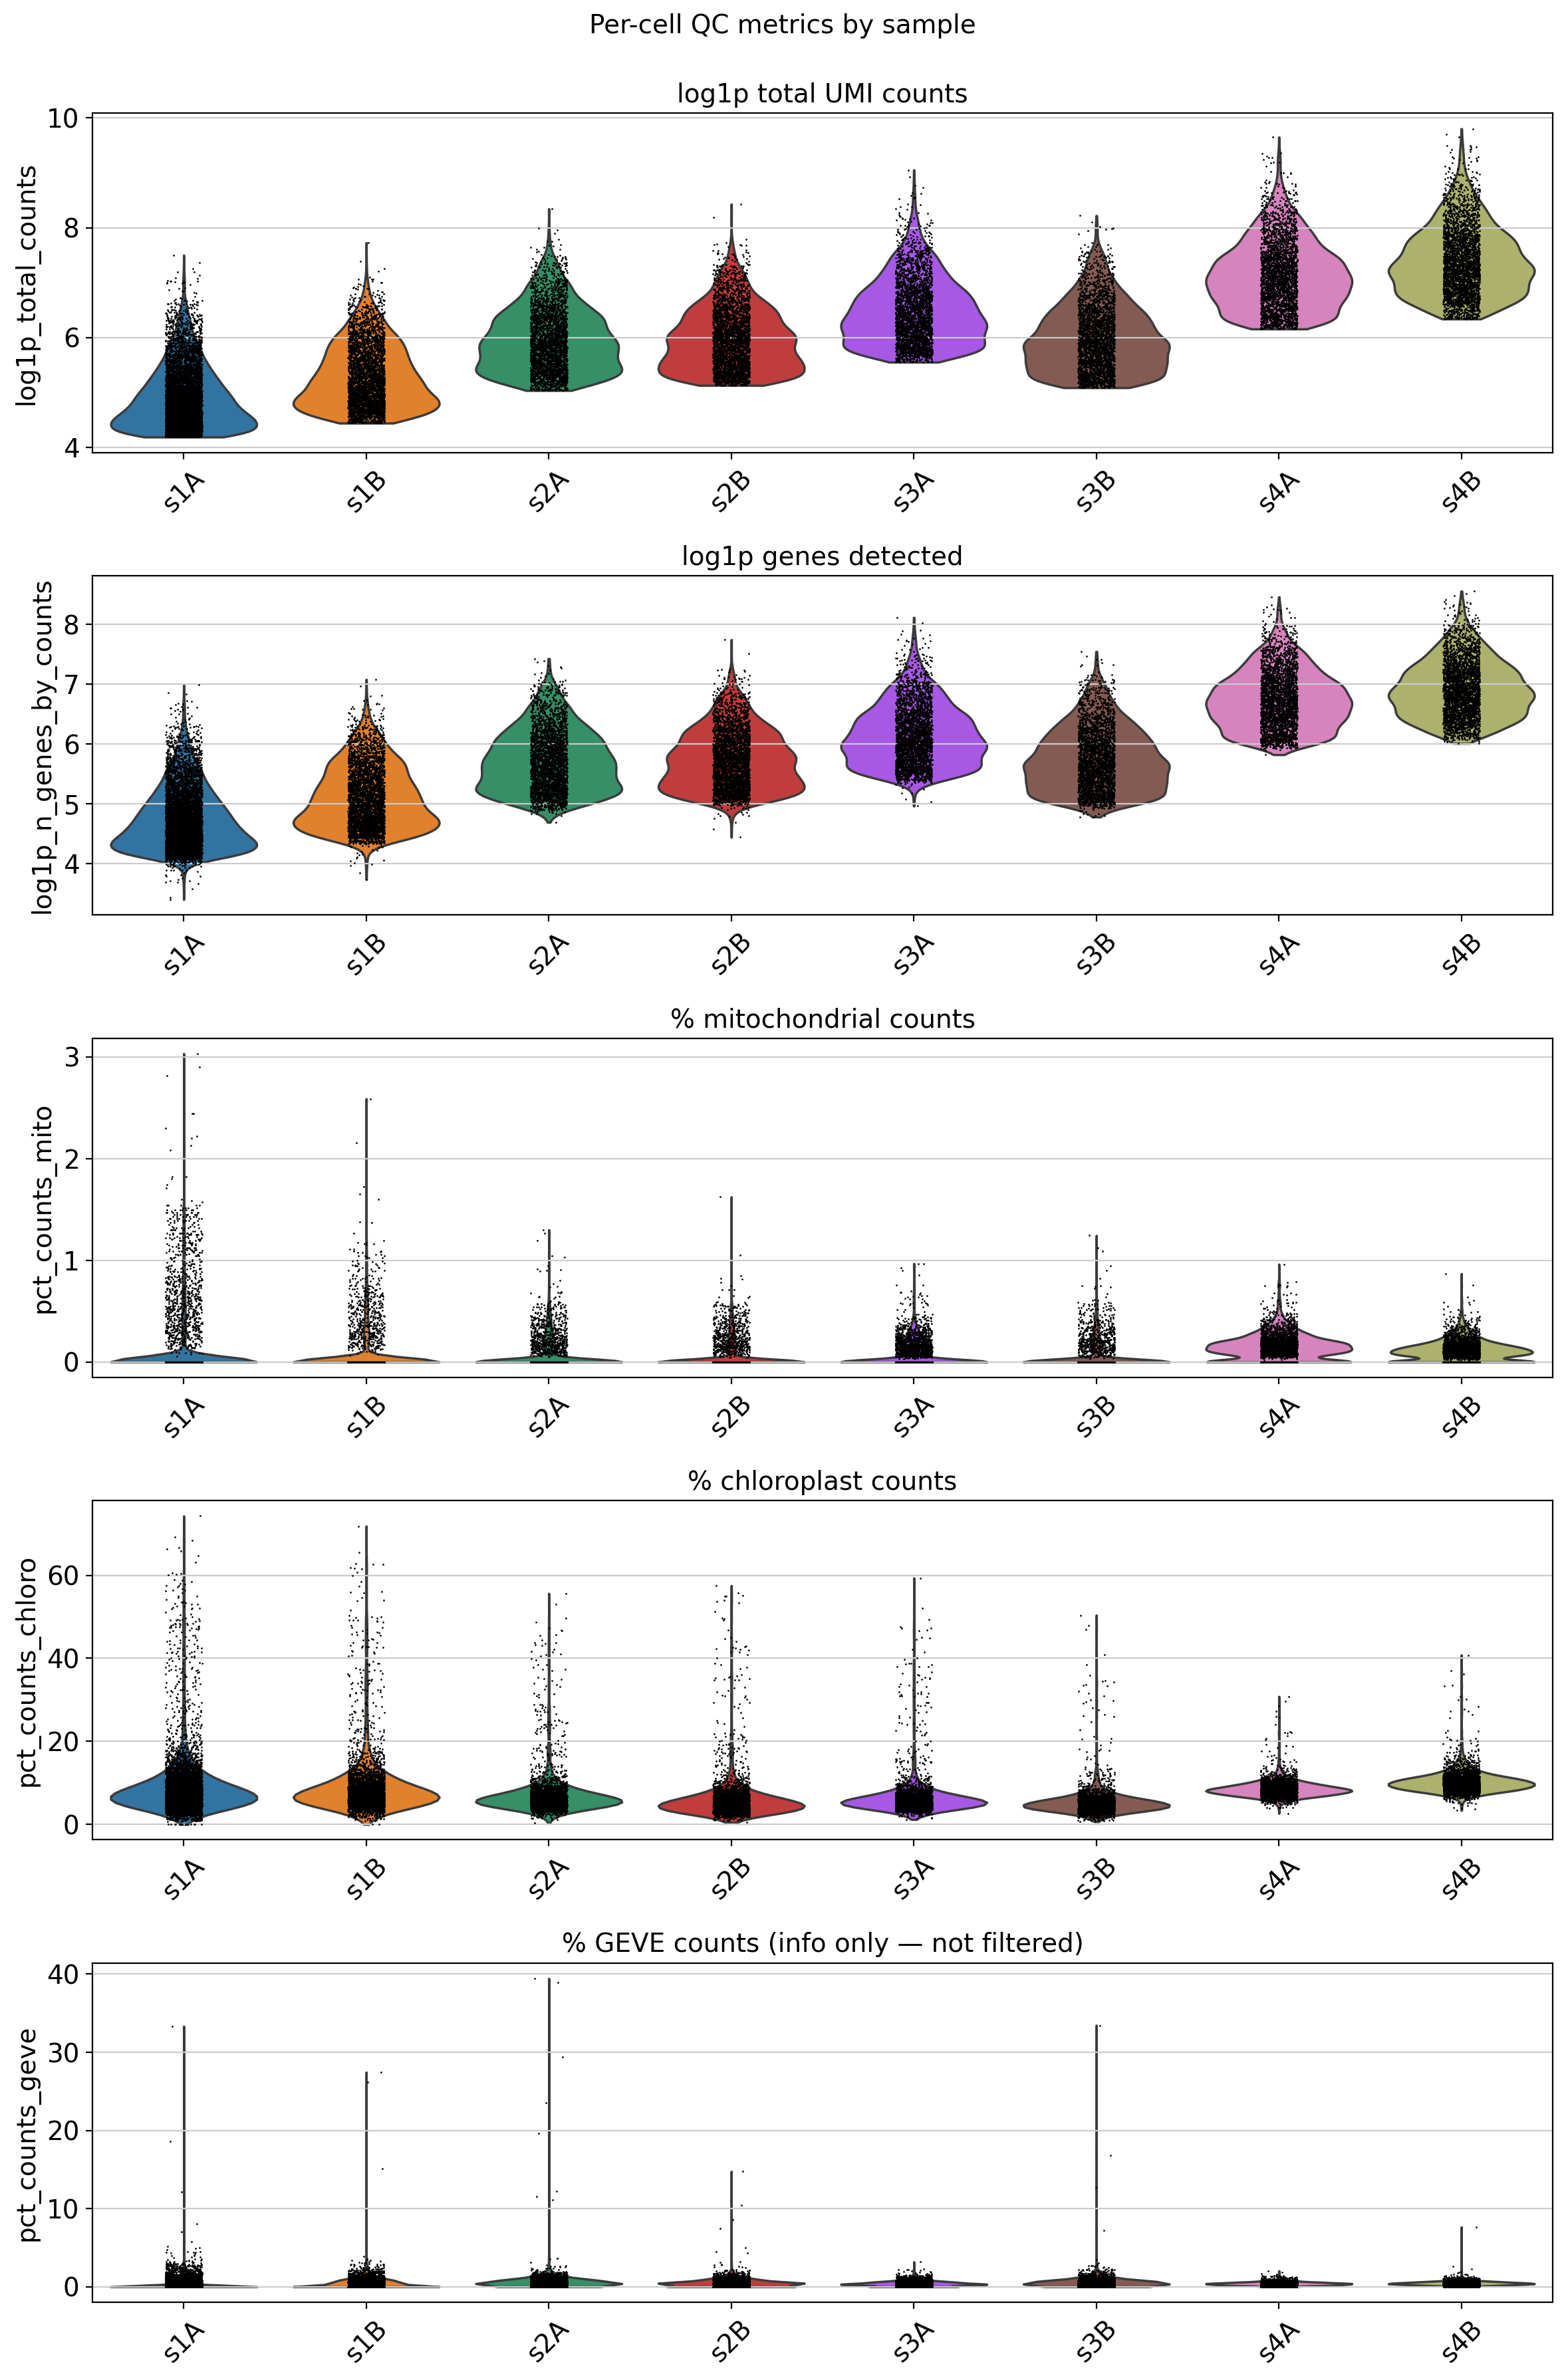

Saved qc_violin_per_sample


In [64]:
# Violin plots — one row per metric, one violin per sample
fig, axes = plt.subplots(5, 1, figsize=(12, 18))
fig.suptitle('Per-cell QC metrics by sample', fontsize=14, y=0.995)

metrics = [
    ('log1p_total_counts',      'log1p total UMI counts'),
    ('log1p_n_genes_by_counts', 'log1p genes detected'),
    ('pct_counts_mito',         '% mitochondrial counts'),
    ('pct_counts_chloro',       '% chloroplast counts'),
    ('pct_counts_geve',         '% GEVE counts (info only — not filtered)'),
]

# Colour by DPI
dpi_palette = {4: '#1f77b4', 5: '#ff7f0e', 6: '#2ca02c', 7: '#d62728'}
sample_dpi  = {s: DPI_MAP[s] for s in SAMPLES}

for ax, (col, label) in zip(axes, metrics):
    sc.pl.violin(
        adata_all, col,
        groupby='sample',
        rotation=45,
        ax=ax,
        show=False
    )
    ax.set_title(label)
    ax.set_xlabel('')

plt.tight_layout()
plt.savefig(FIG_DIR / 'qc_violin_per_sample.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'qc_violin_per_sample.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved qc_violin_per_sample')

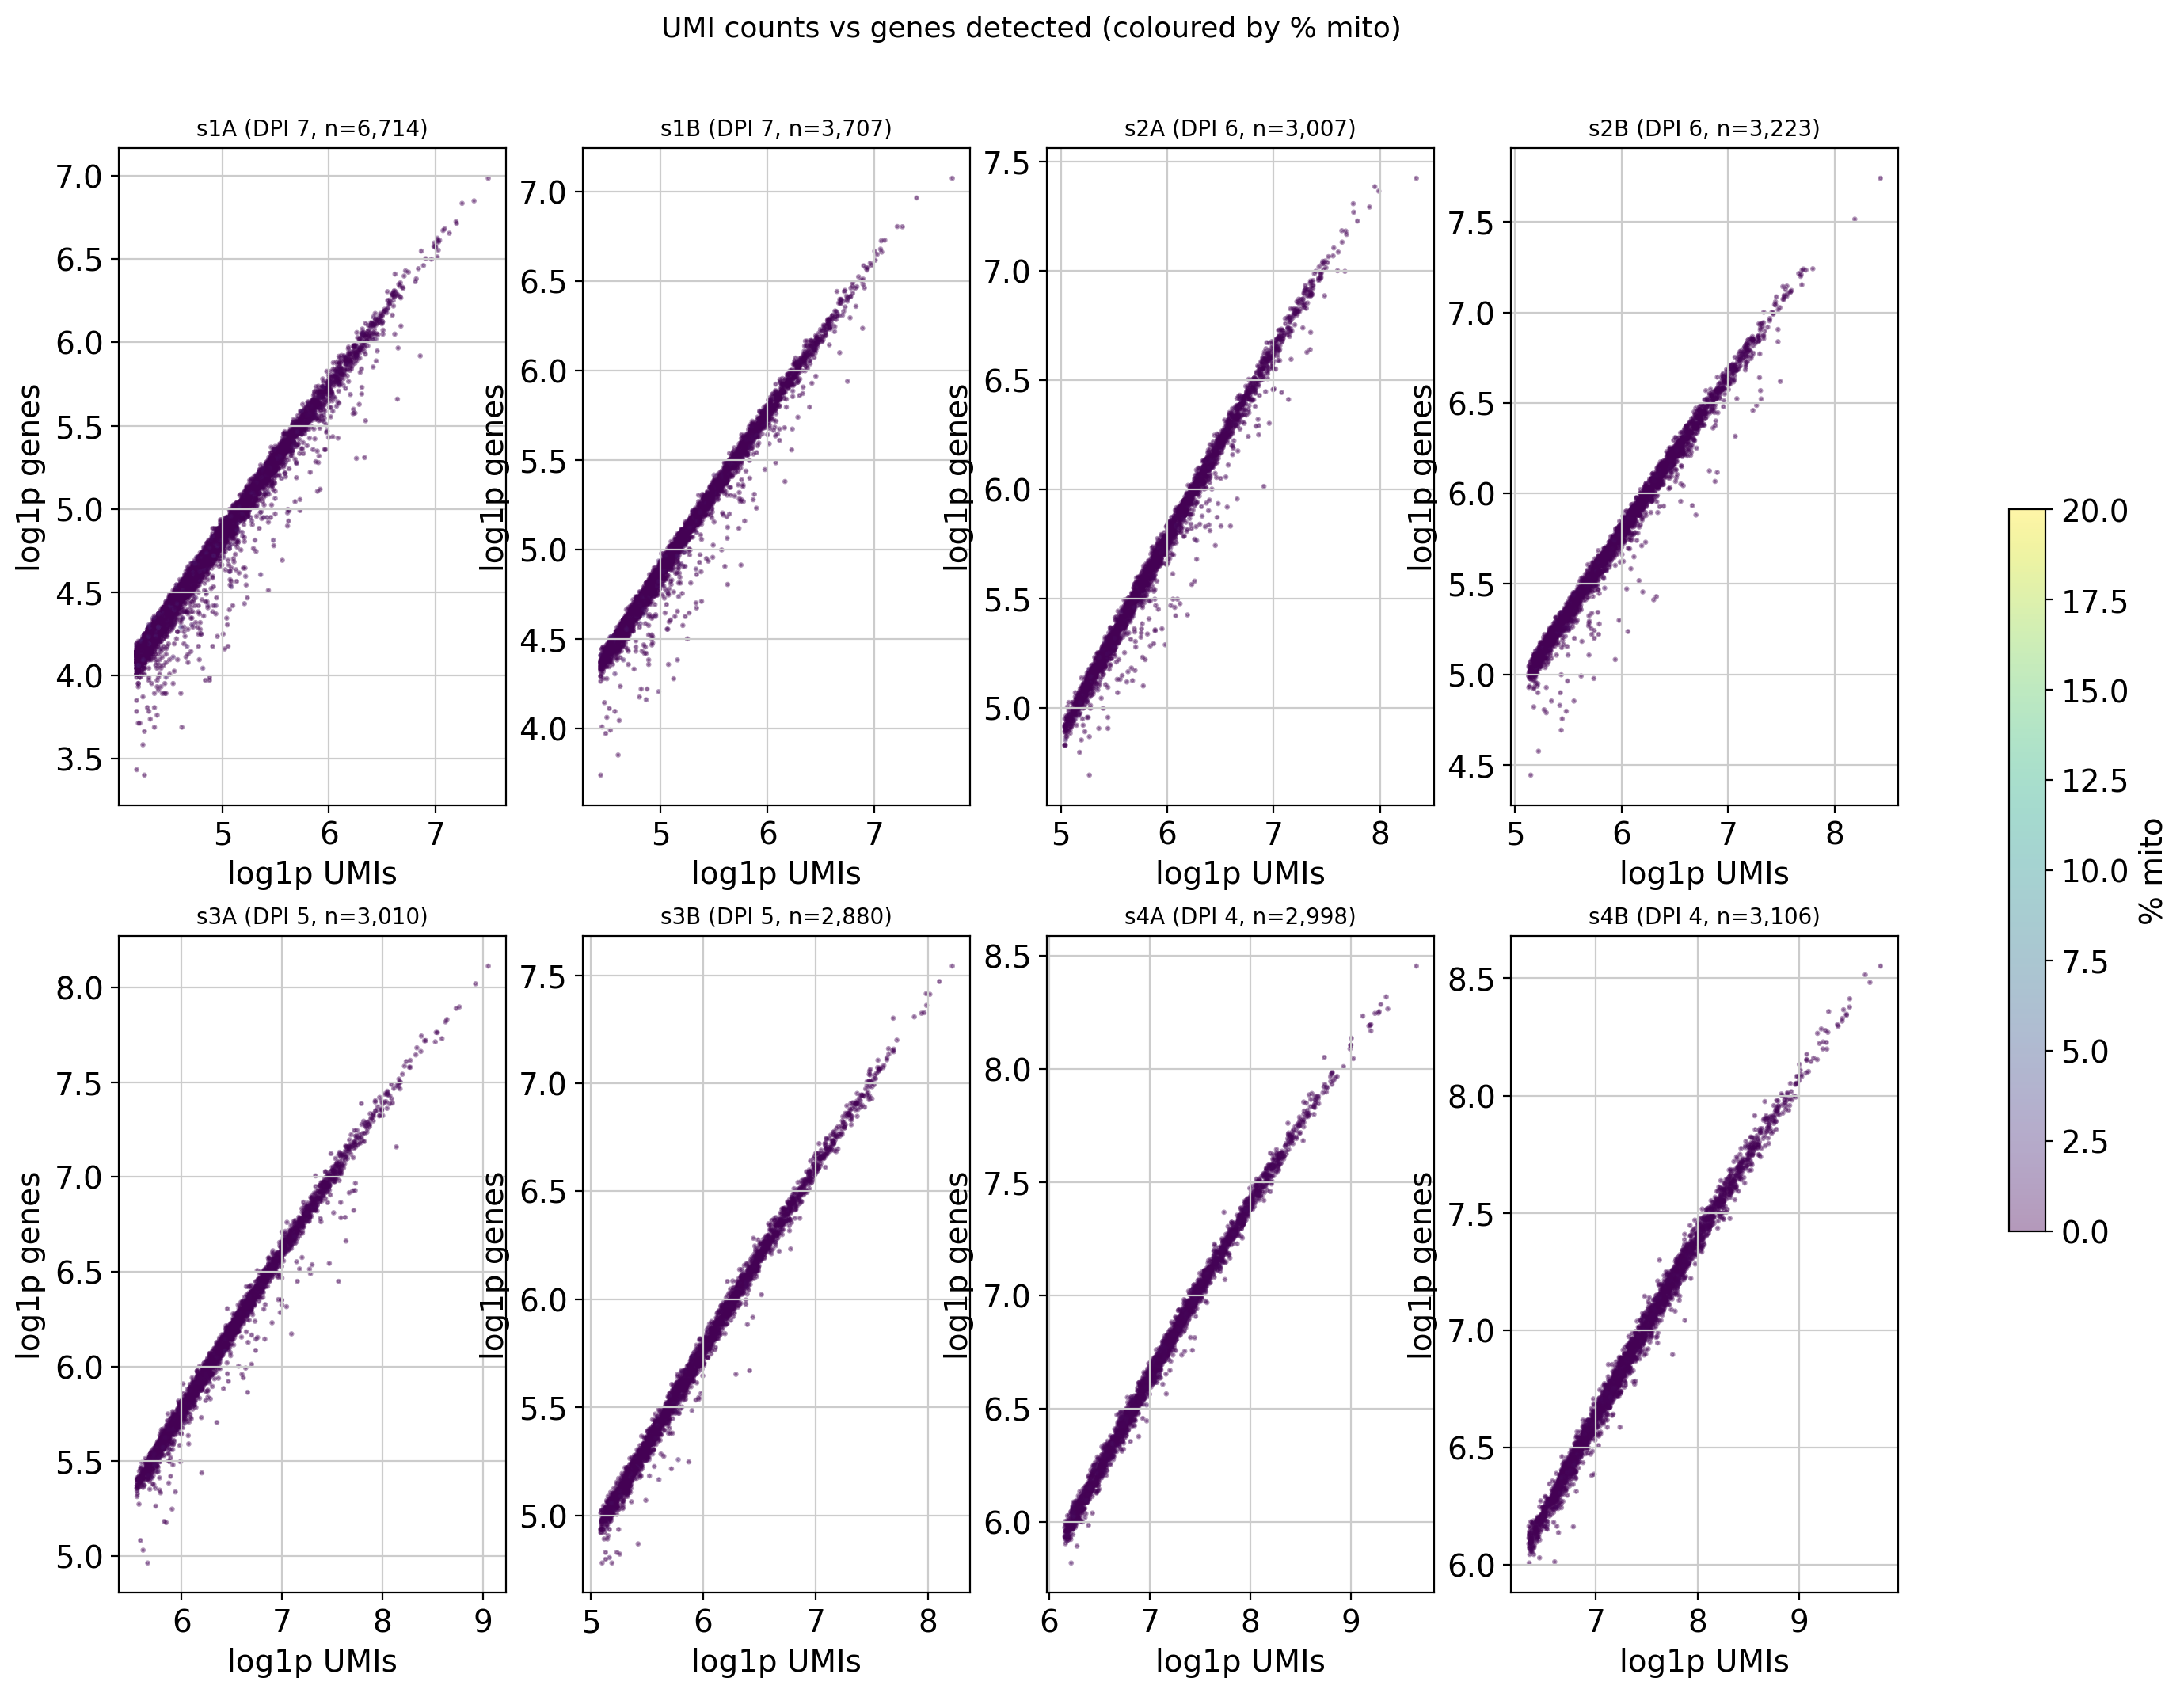

Saved qc_scatter_per_sample


In [65]:
# Scatter: total counts vs genes detected, coloured by mito fraction
fig, axes = plt.subplots(2, 4, figsize=(18,12))
fig.suptitle('UMI counts vs genes detected (coloured by % mito)', fontsize=13)

for ax, sample in zip(axes.flat, SAMPLES):
    mask = adata_all.obs['sample'] == sample
    sub = adata_all.obs[mask]
    sc_plot = ax.scatter(
        sub['log1p_total_counts'],
        sub['log1p_n_genes_by_counts'],
        c=sub['pct_counts_mito'],
        cmap='viridis', s=2, alpha=0.4, vmin=0, vmax=20
    )
    ax.set_title(f"{sample} (DPI {DPI_MAP[sample]}, n={mask.sum():,})", fontsize=10)
    ax.set_xlabel('log1p UMIs')
    ax.set_ylabel('log1p genes')

fig.colorbar(sc_plot, ax=axes.ravel().tolist(), label='% mito', shrink=0.5)
plt.savefig(FIG_DIR / 'qc_scatter_per_sample.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'qc_scatter_per_sample.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved qc_scatter_per_sample')

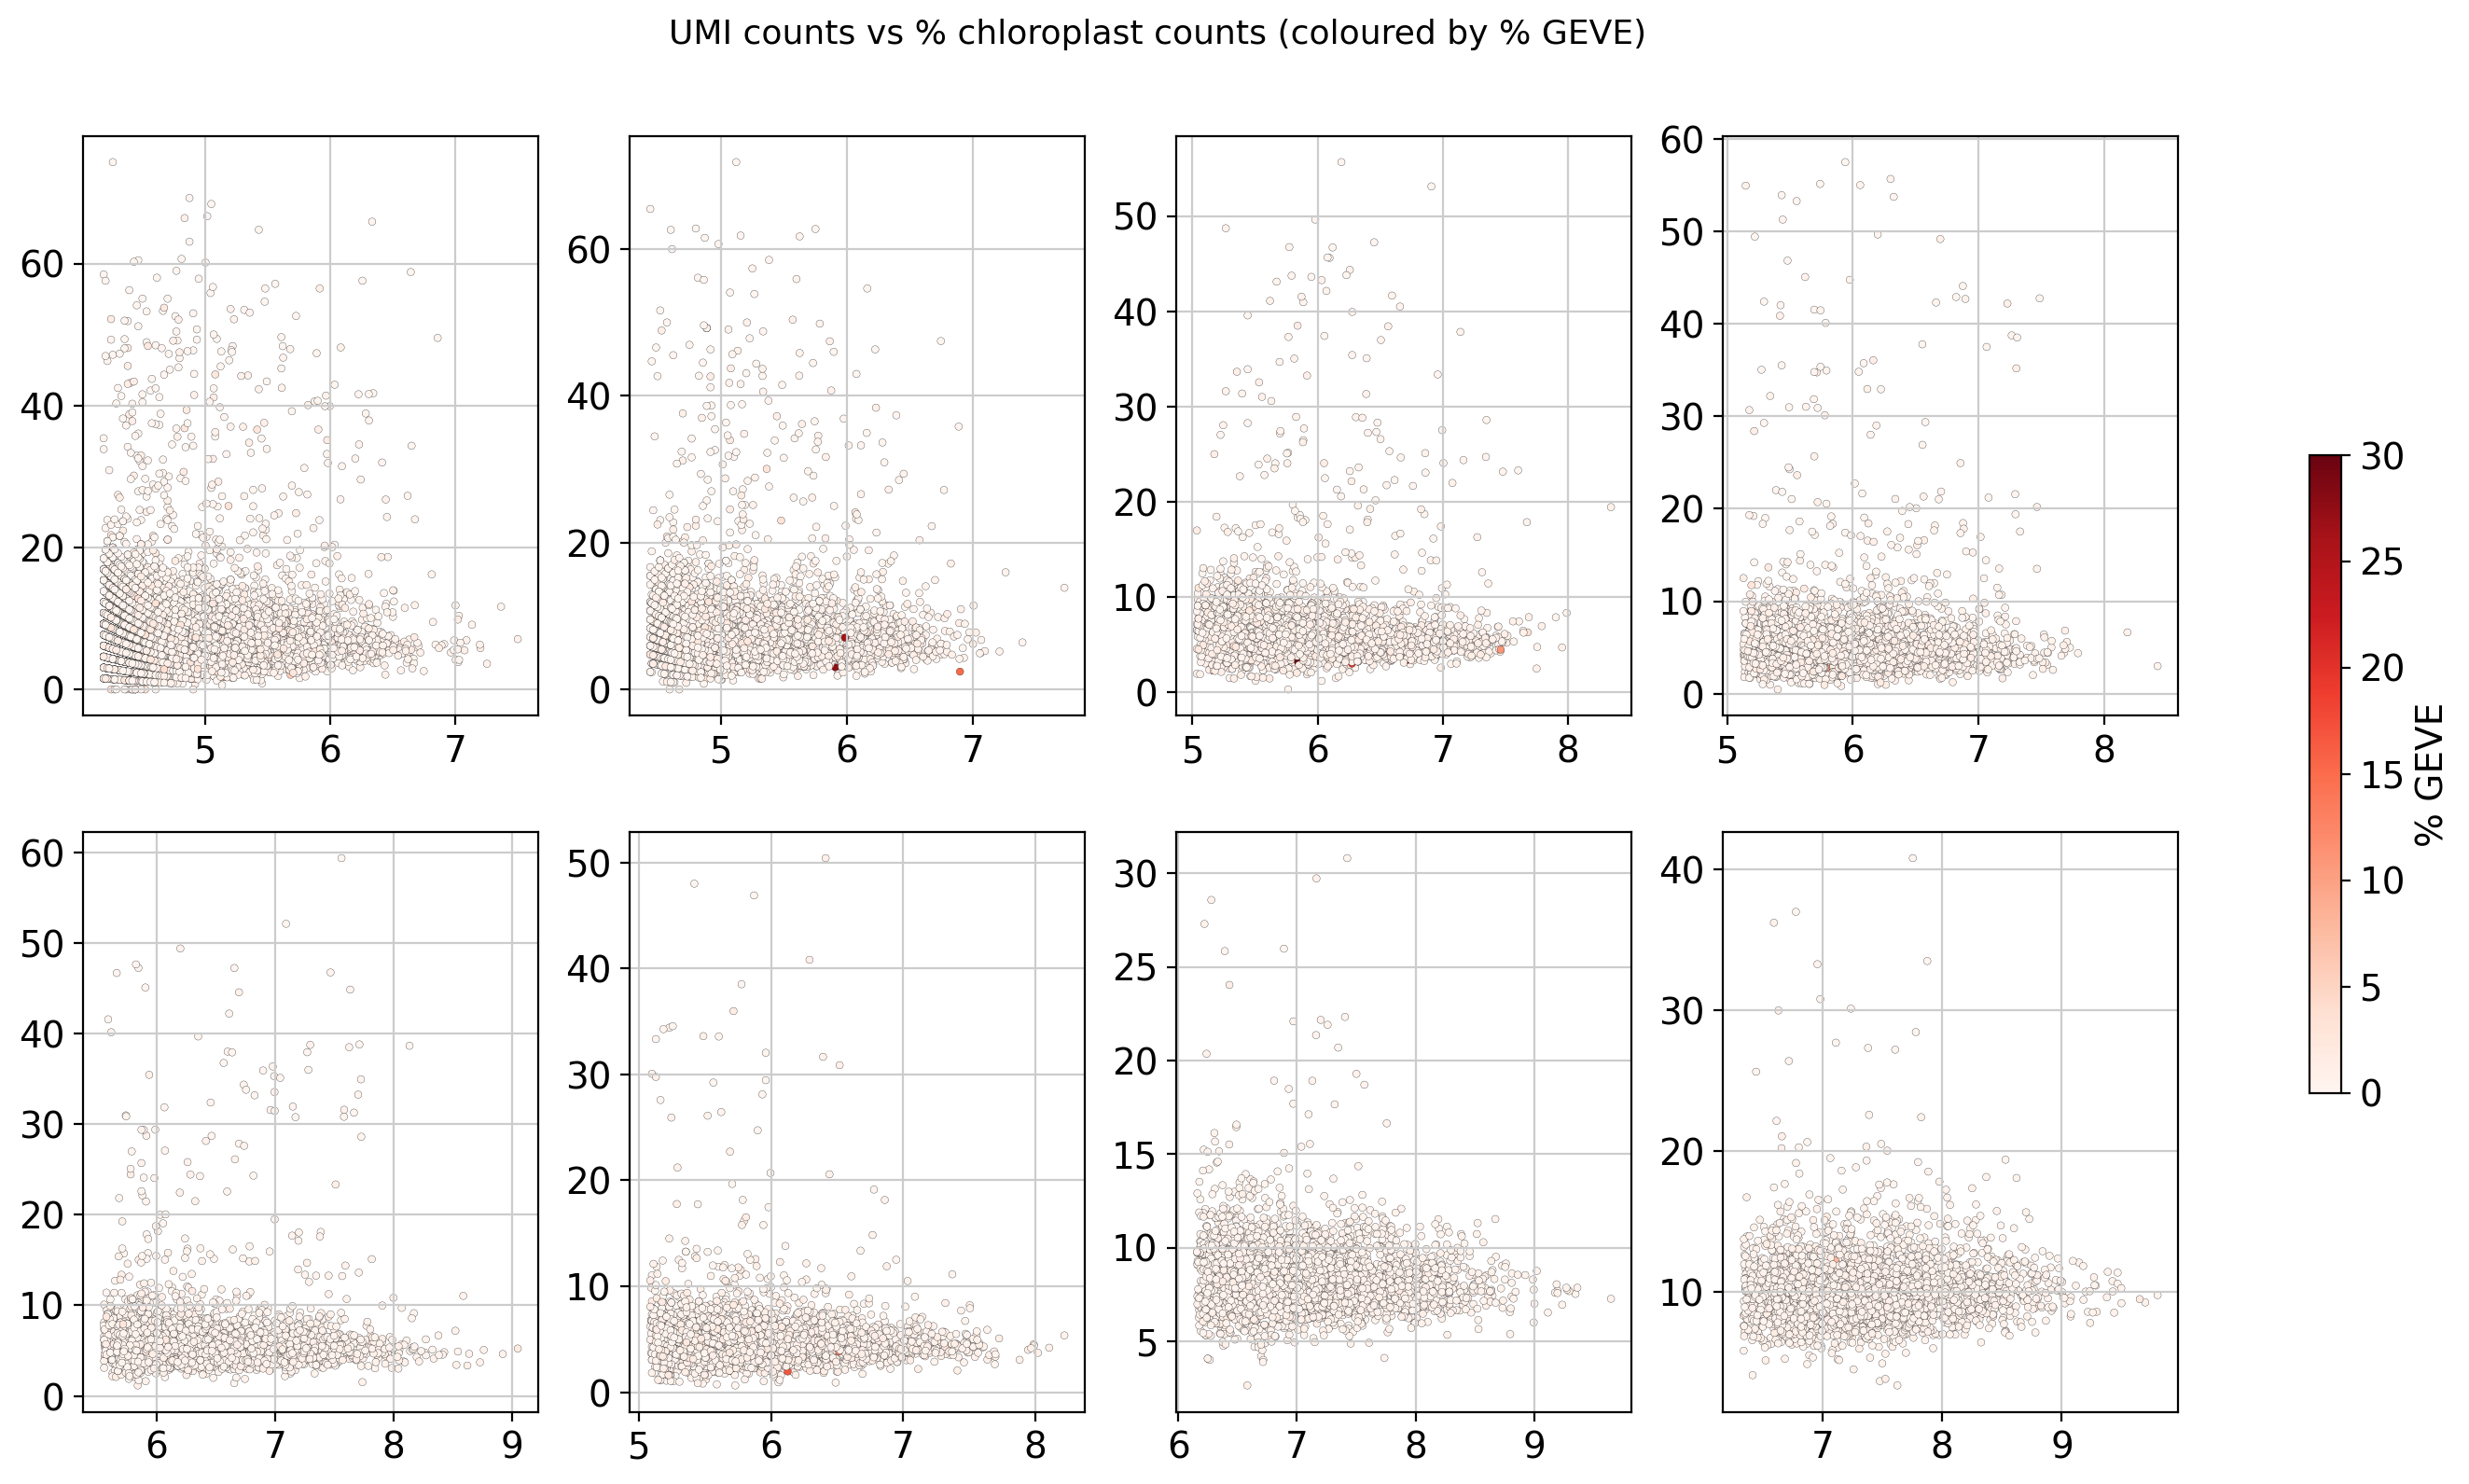

In [69]:
# Scatter: total counts vs chloro fraction (Chlamy-specific damage marker)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('UMI counts vs % chloroplast counts (coloured by % GEVE)', fontsize=13)

for ax, sample in zip(axes.flat, SAMPLES):
    mask = adata_all.obs['sample'] == sample
    sub = adata_all.obs[mask]
    sc_plot = ax.scatter(
        sub['log1p_total_counts'],
        sub['pct_counts_chloro'],
        c=sub['pct_counts_geve'],
        cmap='Reds', 
        s=8,           # Increased size from 2 to 8
        alpha=0.99,     # Increased opacity from 0.4 to 0.8
        edgecolors='black', 
        linewidths=0.1, # Keeps it clean, or try 'black', linewidths=0.1
        vmin=0, 
        vmax=30
    )

fig.colorbar(sc_plot, ax=axes.ravel().tolist(), label='% GEVE', shrink=0.5)
plt.savefig(FIG_DIR / 'qc_scatter_chloro_per_sample.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'qc_scatter_chloro_per_sample.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. MAD-based outlier detection

Applied **per sample** to account for depth variation between samples.  
Thresholds:
- `log1p_total_counts`: ±5 MAD (both tails)
- `log1p_n_genes_by_counts`: ±5 MAD (both tails)
- `pct_counts_mito`: upper tail only (median + 3 MAD)
- `pct_counts_chloro`: upper tail only (median + 5 MAD)
- `pct_counts_in_top_20_genes`: upper tail only (median + 5 MAD)

Using 5 MAD (not 3) for count/gene metrics: preserves rare GEVE+ cells  
that have naturally low Chlamy counts.  
**GEVE fraction is NOT used for filtering.**

In [9]:
def is_outlier(values, n_mads, upper_only=False):
    """Return boolean mask: True = outlier."""
    values = np.array(values, dtype=float)
    med = np.median(values)
    mad = median_abs_deviation(values)
    if upper_only:
        return values > med + n_mads * mad
    else:
        return (values < med - n_mads * mad) | (values > med + n_mads * mad)

outlier_flags = pd.DataFrame(False,
    index=adata_all.obs_names,
    columns=['out_counts', 'out_genes', 'out_mito', 'out_chloro', 'out_top20']
)

for sample in SAMPLES:
    mask = adata_all.obs['sample'] == sample
    obs_sub = adata_all.obs[mask]
    idx = obs_sub.index

    outlier_flags.loc[idx, 'out_counts'] = is_outlier(
        obs_sub['log1p_total_counts'], n_mads=5, upper_only=False)
    outlier_flags.loc[idx, 'out_genes'] = is_outlier(
        obs_sub['log1p_n_genes_by_counts'], n_mads=5, upper_only=False)
    outlier_flags.loc[idx, 'out_mito'] = is_outlier(
        obs_sub['pct_counts_mito'], n_mads=3, upper_only=True)
    outlier_flags.loc[idx, 'out_chloro'] = is_outlier(
        obs_sub['pct_counts_chloro'], n_mads=5, upper_only=True)
    outlier_flags.loc[idx, 'out_top20'] = is_outlier(
        obs_sub['pct_counts_in_top_20_genes'], n_mads=5, upper_only=True)

adata_all.obs['is_outlier'] = outlier_flags.any(axis=1)

# Per-sample outlier summary
print('Outliers per sample:')
for sample in SAMPLES:
    mask = adata_all.obs['sample'] == sample
    n_total = mask.sum()
    n_out   = (adata_all.obs.loc[mask, 'is_outlier']).sum()
    print(f"  {sample}: {n_out:>4}/{n_total} ({100*n_out/n_total:.1f}%) outliers")

print(f"\nTotal outliers: {adata_all.obs['is_outlier'].sum()} / {adata_all.n_obs}")

# Per-criterion breakdown (global)
print('\nOutlier breakdown by criterion:')
for col in outlier_flags.columns:
    adata_all.obs[col] = outlier_flags[col]
    print(f"  {col}: {outlier_flags[col].sum():,} cells")

Outliers per sample:
  s1A: 1213/6714 (18.1%) outliers
  s1B:  750/3707 (20.2%) outliers
  s2A:  875/3007 (29.1%) outliers
  s2B:  816/3223 (25.3%) outliers
  s3A: 1346/3010 (44.7%) outliers
  s3B:  734/2880 (25.5%) outliers
  s4A:  227/2998 (7.6%) outliers
  s4B:  263/3106 (8.5%) outliers

Total outliers: 6224 / 28645

Outlier breakdown by criterion:
  out_counts: 66 cells
  out_genes: 39 cells
  out_mito: 5,195 cells
  out_chloro: 1,246 cells
  out_top20: 586 cells


In [10]:
# Filter outlier cells
n_before = adata_all.n_obs
adata_all = adata_all[~adata_all.obs['is_outlier']].copy()
n_after = adata_all.n_obs
print(f'Cells retained: {n_after:,} / {n_before:,} ({100*n_after/n_before:.1f}%)')

Cells retained: 22,421 / 28,645 (78.3%)


## 6. Per-gene filter

Remove genes detected in fewer than **20 cells** across the merged (post-cell-filter) dataset.  
**Exception**: all 528 GEVE genes are always retained regardless of detection frequency.

In [11]:
# Count cells with ≥1 UMI per gene
gene_cell_counts = (adata_all.X > 0).sum(axis=0)
if hasattr(gene_cell_counts, 'A1'):
    gene_cell_counts = np.asarray(gene_cell_counts).flatten()
else:
    gene_cell_counts = np.asarray(gene_cell_counts).flatten()

adata_all.var['n_cells_detected'] = gene_cell_counts

# Keep if ≥20 cells OR is a GEVE gene
keep_gene = (gene_cell_counts >= 20) | (adata_all.var['gene_type'] == 'GEVE')

n_before = adata_all.n_vars
adata_filt = adata_all[:, keep_gene].copy()
n_after = adata_filt.n_vars

print(f'Genes retained: {n_after:,} / {n_before:,}')
print('Gene type breakdown after filter:')
print(adata_filt.var['gene_type'].value_counts().to_string())

# Confirm all GEVE genes retained
n_geve = (adata_filt.var['gene_type'] == 'GEVE').sum()
print(f'\nGEVE genes retained: {n_geve} (expected 528)')

Genes retained: 15,036 / 17,559
Gene type breakdown after filter:
gene_type
chlamy    14376
GEVE        528
chloro      125
mito          7

GEVE genes retained: 528 (expected 528)


## 7. Doublet detection with scrublet

Run **per sample** (scrublet simulates doublets from the same sample's pool).  
Doublet scores are stored in `obs['doublet_score']` and `obs['predicted_doublet']`.  
**Removal is deferred to post-clustering inspection** — doublets will be visible as cells  
with mixed-sample transcriptomes in the UMAP.

Expected doublet rate for Parse SPLiT-seq: ~1–3% (lower than droplet-based methods).

In [12]:
try:
    import scrublet as scr
    HAS_SCRUBLET = True
    print('scrublet imported')
except ImportError:
    HAS_SCRUBLET = False
    print('scrublet not installed — run: pip install scrublet')
    print('Doublet detection skipped; continuing with rest of QC.')

if HAS_SCRUBLET:
    import scipy.sparse as sp

    doublet_score   = np.full(adata_filt.n_obs, np.nan)
    predicted_dbl   = np.full(adata_filt.n_obs, False)

    for sample in SAMPLES:
        mask = adata_filt.obs['sample'] == sample
        idx  = np.where(mask)[0]
        counts_sub = adata_filt[mask].X

        if sp.issparse(counts_sub):
            counts_sub = counts_sub.toarray()

        scrub = scr.Scrublet(counts_sub, expected_doublet_rate=0.02)
        scores, calls = scrub.scrub_doublets(min_counts=2, min_cells=3, verbose=False)

        doublet_score[idx] = scores
        predicted_dbl[idx] = calls

        n_dbl = calls.sum()
        pct   = 100 * n_dbl / len(calls)
        print(f"  {sample}: {n_dbl}/{len(calls)} predicted doublets ({pct:.1f}%)")

    adata_filt.obs['doublet_score']     = doublet_score
    adata_filt.obs['predicted_doublet'] = predicted_dbl

    total_dbl = predicted_dbl.sum()
    print(f"\nTotal predicted doublets: {total_dbl:,} / {adata_filt.n_obs:,} "
          f"({100*total_dbl/adata_filt.n_obs:.1f}%)")
    print('Doublets NOT removed — inspect on UMAP after clustering.')
else:
    adata_filt.obs['doublet_score']     = np.nan
    adata_filt.obs['predicted_doublet'] = False

scrublet imported


  s1A: 5126/5501 predicted doublets (93.2%)


  s1B: 6/2957 predicted doublets (0.2%)


  s2A: 2/2132 predicted doublets (0.1%)


  s2B: 2/2407 predicted doublets (0.1%)


  s3A: 0/1664 predicted doublets (0.0%)


  s3B: 2/2146 predicted doublets (0.1%)


  s4A: 1/2771 predicted doublets (0.0%)


  s4B: 4/2843 predicted doublets (0.1%)

Total predicted doublets: 5,143 / 22,421 (22.9%)
Doublets NOT removed — inspect on UMAP after clustering.


## 8. Store raw counts and save

Raw counts are stored in `layers['counts']` before any normalization.  
All downstream analyses must use `layers['counts']` as the source for `adata.X`  
when starting from scratch (e.g., before `sc.pp.normalize_total()`).

In [13]:
import scipy.sparse as sp

# Store raw counts
adata_filt.layers['counts'] = adata_filt.X.copy()

# Add GEVE classification to obs
# Use toarray().ravel() to avoid numpy.matrix flatten() quirk with sparse column slices
geve_X = adata_filt[:, adata_filt.var['is_geve']].X
geve_sum = geve_X.sum(axis=1)
adata_filt.obs['geve_raw'] = np.array(geve_sum).ravel()
adata_filt.obs['geve_pos']  = adata_filt.obs['geve_raw'] > 0
adata_filt.obs['geve_hi4']  = adata_filt.obs['geve_raw'] > 4
adata_filt.obs['geve_hi28'] = adata_filt.obs['geve_raw'] > 28

# MCP raw counts (GEVEv2_329)
mcp_gene = 'GEVEv2_329'
if mcp_gene in adata_filt.var_names:
    mcp_col = adata_filt[:, mcp_gene].X
    # toarray() always returns a proper ndarray (not numpy.matrix)
    if sp.issparse(mcp_col):
        adata_filt.obs['mcp_raw'] = mcp_col.toarray().ravel()
    else:
        adata_filt.obs['mcp_raw'] = np.array(mcp_col).ravel()
    adata_filt.obs['mcp_pos'] = adata_filt.obs['mcp_raw'] > 0
else:
    print(f'WARNING: {mcp_gene} not found in var_names')
    adata_filt.obs['mcp_raw'] = 0
    adata_filt.obs['mcp_pos'] = False

# Summary
print('=== Final AnnData Summary ===')
print(f'Cells:  {adata_filt.n_obs:,}')
print(f'Genes:  {adata_filt.n_vars:,}')
print(f'  GEVE: {(adata_filt.var["gene_type"]=="GEVE").sum()}')
print(f'  Chlamy: {(adata_filt.var["gene_type"]=="chlamy").sum()}')
print(f'  Chloro: {(adata_filt.var["gene_type"]=="chloro").sum()}')
print(f'  Mito: {(adata_filt.var["gene_type"]=="mito").sum()}')
print(f'GEVE+: {adata_filt.obs["geve_pos"].sum():,} cells ({100*adata_filt.obs["geve_pos"].mean():.1f}%)')
print(f'GEVE>4: {adata_filt.obs["geve_hi4"].sum():,} cells')
print(f'GEVE>28: {adata_filt.obs["geve_hi28"].sum():,} cells')
print(f'MCP+: {adata_filt.obs["mcp_pos"].sum():,} cells')

out_path = ADATA_DIR / 'adata_all_qc.h5ad'
adata_filt.write_h5ad(out_path)
print(f'\nSaved to: {out_path}')


=== Final AnnData Summary ===
Cells:  22,421
Genes:  15,036
  GEVE: 528
  Chlamy: 14376
  Chloro: 125
  Mito: 7
GEVE+: 15,640 cells (69.8%)
GEVE>4: 4,688 cells
GEVE>28: 154 cells
MCP+: 37 cells



Saved to: adata/adata_all_qc.h5ad


## 9. QC summary figure

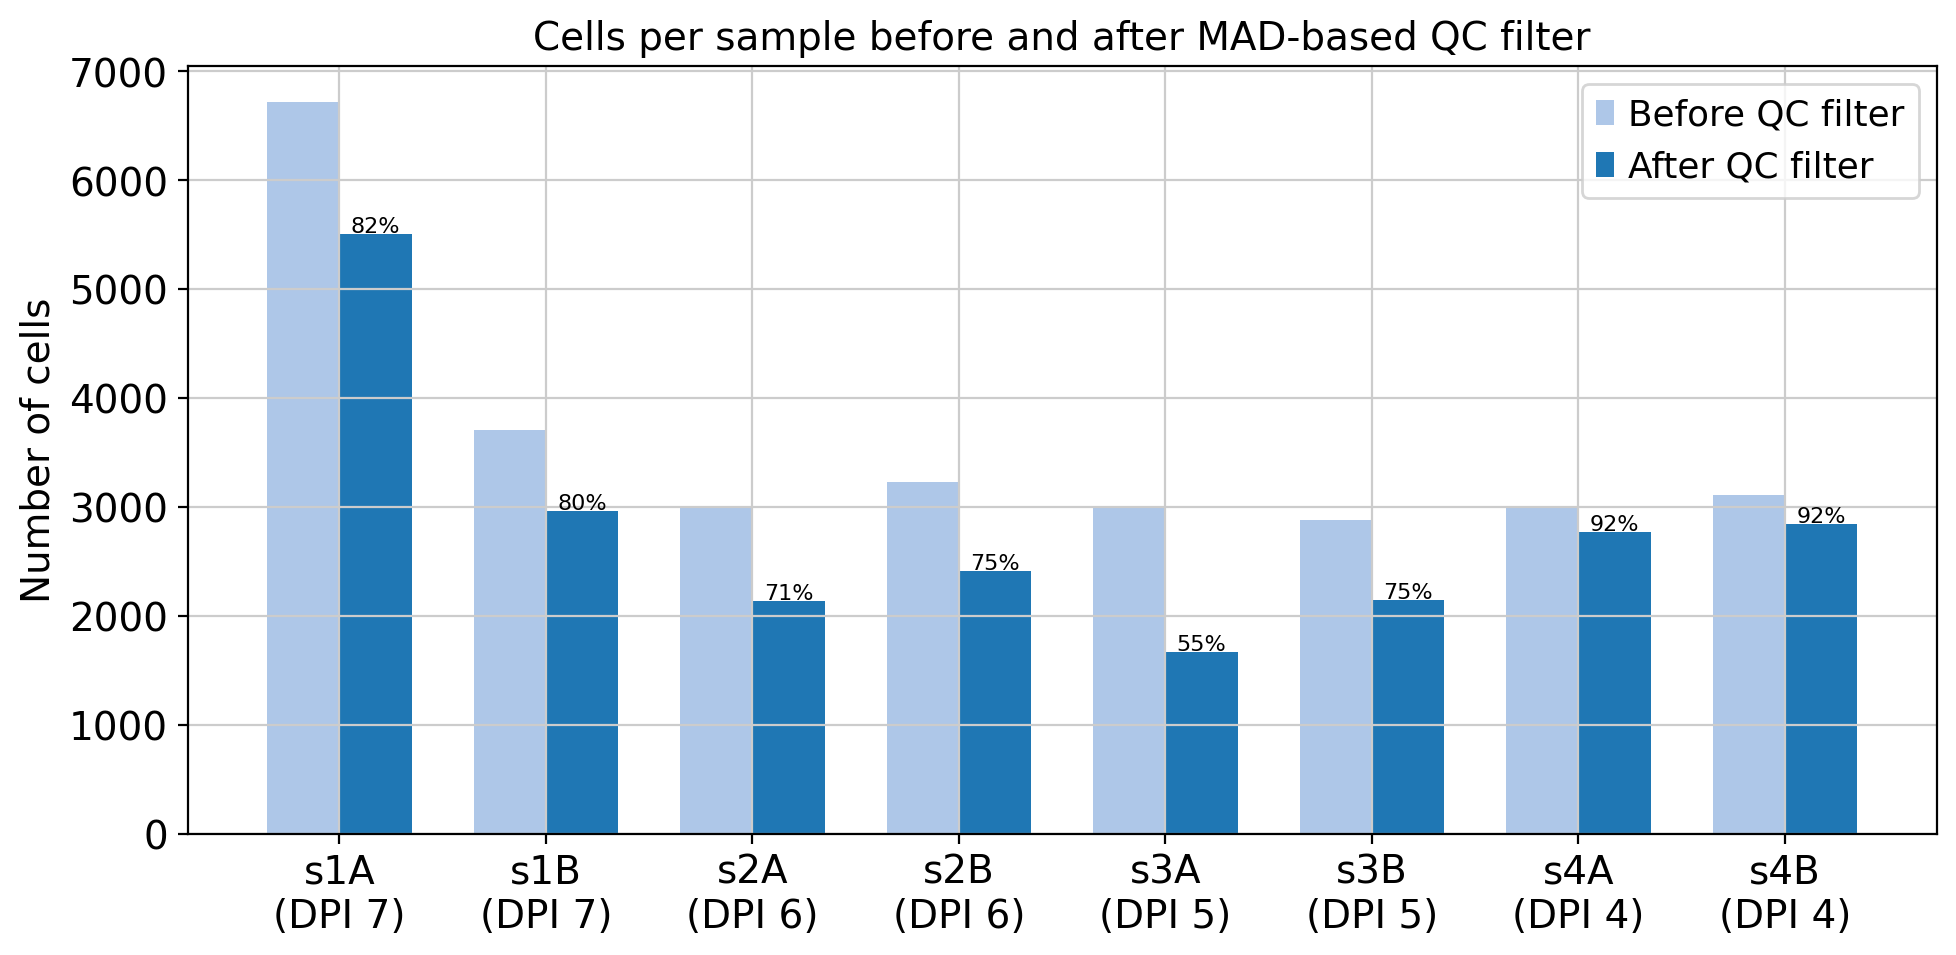

In [14]:
# Cells per sample before/after
before_dict = {}
for sample in SAMPLES:
    # reload original counts
    mtx_path = DATA_DIR / sample / 'DGE_filtered' / 'count_matrix.mtx'
    with open(mtx_path) as f:
        for line in f:
            if line.startswith('%Rows='):
                n = int(line.split('(')[1].split(')')[0])
                before_dict[sample] = n
                break

after_dict = adata_filt.obs.groupby('sample').size().to_dict()

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(SAMPLES))
w = 0.35
bars1 = ax.bar(x - w/2, [before_dict[s] for s in SAMPLES], w,
               label='Before QC filter', color='#aec7e8')
bars2 = ax.bar(x + w/2, [after_dict.get(s, 0) for s in SAMPLES], w,
               label='After QC filter', color='#1f77b4')
ax.set_xticks(x)
ax.set_xticklabels([f"{s}\n(DPI {DPI_MAP[s]})" for s in SAMPLES])
ax.set_ylabel('Number of cells')
ax.set_title('Cells per sample before and after MAD-based QC filter')
ax.legend()

# Annotate % retained
for i, sample in enumerate(SAMPLES):
    pct = 100 * after_dict.get(sample, 0) / before_dict[sample]
    ax.text(i + w/2, after_dict.get(sample, 0) + 20, f'{pct:.0f}%', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / 'qc_cells_retained.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'qc_cells_retained.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
# GEVE+ breakdown per DPI
print('GEVE+ cells per DPI:')
geve_summary = adata_filt.obs.groupby('dpi').agg(
    n_cells=('geve_pos', 'count'),
    n_geve_pos=('geve_pos', 'sum'),
    n_geve_hi4=('geve_hi4', 'sum'),
    n_mcp_pos=('mcp_pos', 'sum'),
    median_geve_raw=('geve_raw', 'median')
).assign(
    pct_geve_pos=lambda df: 100 * df['n_geve_pos'] / df['n_cells']
).round(1)
print(geve_summary.to_string())

GEVE+ cells per DPI:
     n_cells  n_geve_pos  n_geve_hi4  n_mcp_pos  median_geve_raw  pct_geve_pos
dpi                                                                           
4       5614        5442        3410          6              6.0          96.9
5       3810        3068         570          5              2.0          80.5
6       4539        3464         574         22              2.0          76.3
7       8458        3666         134          4              0.0          43.3
